In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import files

In [2]:
os.makedirs('images', exist_ok=True)

print("Please Upload The Required Images:")
print("- blox.jpg")
print("- box.png")
print("- box_in_scene.png")

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f"File '{filename}' Moved To '{dest}'.")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Please Upload The Required Images:
- blox.jpg
- box.png
- box_in_scene.png


Saving blox.jpg to blox.jpg
Saving box.png to box.png
Saving box_in_scene.png to box_in_scene.png
File 'blox.jpg' Moved To 'images/blox.jpg'.
File 'box.png' Moved To 'images/box.png'.
File 'box_in_scene.png' Moved To 'images/box_in_scene.png'.

Contents Of Images Folder:
['blox.jpg', 'box_in_scene.png', 'box.png']


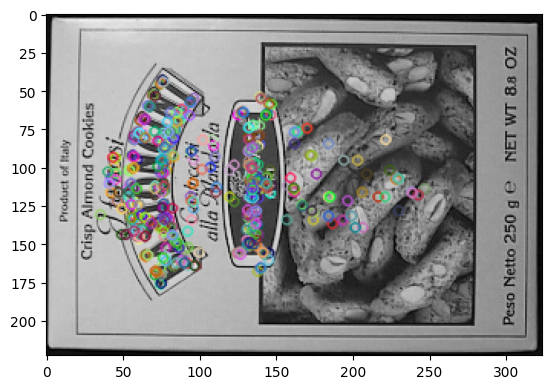

In [3]:
img = cv2.imread('images/box.png')
img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

orb = cv2.ORB_create()
kp = orb.detect(img_gray, None)

img = cv2.drawKeypoints(img, kp, img)

plt.imshow(img)

plt.show()

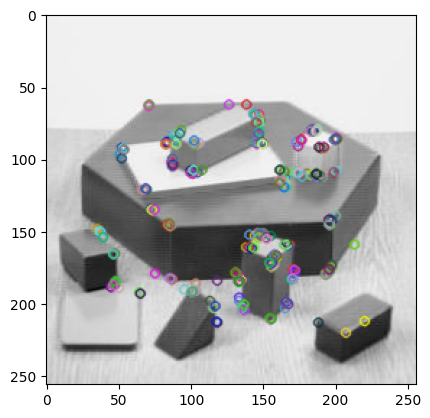

In [4]:
img = cv2.imread('images/blox.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

orb = cv2.ORB_create()

kp = orb.detect(img, None)
kp, des = orb.compute(img, kp)

img = cv2.drawKeypoints(img, kp, img)

plt.imshow(img)

plt.show()

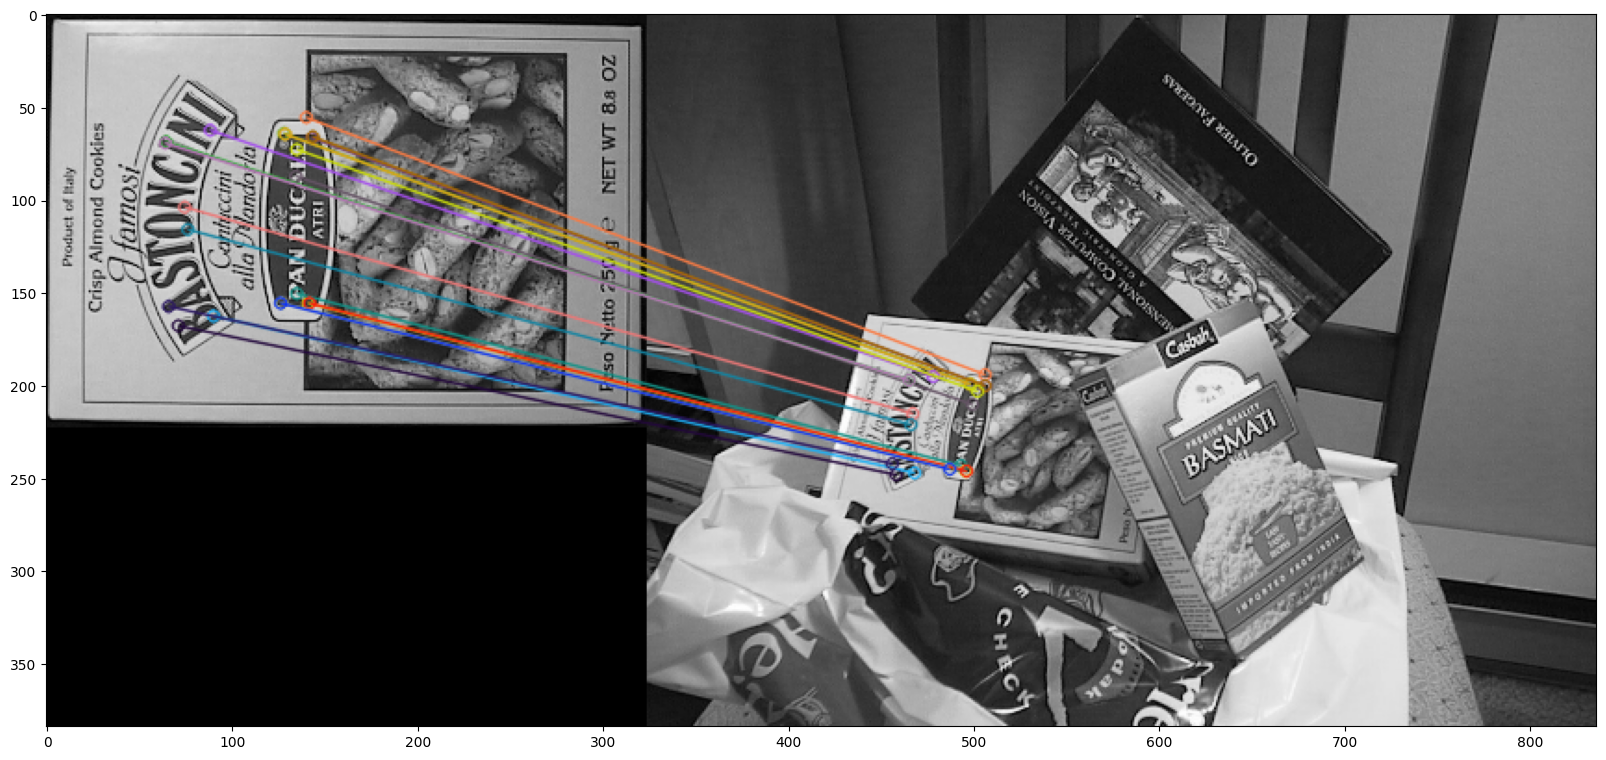

In [5]:
img1 = cv2.imread('images/box.png')
img2 = cv2.imread('images/box_in_scene.png')

sift = cv2.ORB_create()

kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)

matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda x: x.distance)

img_result = cv2.drawMatches(img1, kp1, img2, kp2, matches[:20], img2, flags=cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(20, 10))

plt.imshow(img_result[..., ::-1])

plt.show()